# Loan Approval Prediction

## 1. Problem

Assessing loan applications requires understanding the applicant characteristics associated with loan approval. This project investigates patterns in loan application data to predict whether an application will be approved or rejected.

The problem is important because analyzing these patterns can support a better understanding of lending decisions and the characteristics of different applicant groups.

## 2. Data Mining Task

This project addresses two data mining tasks:

- **Classification:** Use Decision Tree classifiers with Gini and Entropy to predict Loan_Status: approved (Y) or rejected (N).
- **Clustering:** Use K-means to group applicants with similar characteristics and investigate the patterns within these groups.

## 3. Data

### 3.1 Dataset Source

The dataset was obtained from Kaggle.

Dataset Name: Loan Approval Prediction Dataset

Source: Kaggle

URL: https://www.kaggle.com/datasets/priyanshsharma6207/loan-approval-prediction-dataset

### 3.2 Dataset Description

The raw dataset contains information about loan applicants and their loan applications. It has 953 records and 13 attributes, including the identifier Loan_ID and the class attribute Loan_Status.

The attributes describe applicant characteristics and loan details, such as gender, marital status, dependents, education, employment status, income, loan amount, loan term, credit history, and property area.

Loan_Status has two classes:
- Y: Loan approved.
- N: Loan not approved.


In [2]:
import pandas as pd

df = pd.read_csv("Raw_dataset.csv")

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 953
Number of columns: 13


### 3.3 Data Types

The following output shows the data type and number of non-null values for each attribute in the raw dataset.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 953 entries, 0 to 952
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            953 non-null    object 
 1   Gender             929 non-null    object 
 2   Married            949 non-null    object 
 3   Dependents         930 non-null    object 
 4   Education          953 non-null    object 
 5   Self_Employed      903 non-null    object 
 6   ApplicantIncome    953 non-null    int64  
 7   CoapplicantIncome  953 non-null    float64
 8   LoanAmount         921 non-null    float64
 9   Loan_Amount_Term   935 non-null    float64
 10  Credit_History     872 non-null    float64
 11  Property_Area      953 non-null    object 
 12  Loan_Status        953 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 96.9+ KB


### 3.4 Class Attribute

The class attribute is Loan_Status. It contains two classes:
- Y: Loan approved.
- N: Loan not approved.

The following output shows the number of records in each class.

In [4]:
df.groupby("Loan_Status")["Loan_ID"].count()

,Loan_ID
Loan_Status,
N,309
Y,644


### 3.5 Sample of Raw Dataset

The following table shows the first five records of the raw dataset before preprocessing.

In [5]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [6]:
import pandas as pd
import matplotlib.pyplot as plt

df=pd.read_csv("Raw_dataset.csv")

In [7]:
shape = df.shape
print(shape)

(953, 13)


### 3.6 Data Analysis


### 3.6.1  Dataset Overview

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 953 entries, 0 to 952
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            953 non-null    object 
 1   Gender             929 non-null    object 
 2   Married            949 non-null    object 
 3   Dependents         930 non-null    object 
 4   Education          953 non-null    object 
 5   Self_Employed      903 non-null    object 
 6   ApplicantIncome    953 non-null    int64  
 7   CoapplicantIncome  953 non-null    float64
 8   LoanAmount         921 non-null    float64
 9   Loan_Amount_Term   935 non-null    float64
 10  Credit_History     872 non-null    float64
 11  Property_Area      953 non-null    object 
 12  Loan_Status        953 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 96.9+ KB



The dataset contains 953 records and 13 attributes, including numerical and categorical data. Some attributes contain missing values, indicating that data cleaning is required during preprocessing.

### 3.6.2 Statistical Summary

In [9]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,953.000000,953.000000,921.000000,935.000000,872.000000
mean,5433.144806,1671.703085,146.163952,340.979679,0.829128
std,6288.391469,3164.094759,84.654966,65.987724,0.376613
min,150.000000,0.000000,9.000000,12.000000,0.000000
25%,2873.000000,0.000000,100.000000,360.000000,1.000000
50%,3775.000000,1250.000000,128.000000,360.000000,1.000000
75%,5818.000000,2306.000000,166.000000,360.000000,1.000000
max,81002.000000,41667.000000,700.000000,480.000000,1.000000


The statistical summary shows large differences between the mean and maximum values of ApplicantIncome and CoapplicantIncome, indicating skewed distributions and potential outliers. These attributes may require further analysis and normalization during preprocessing.

### 3.6.3 Five-Number Summary

In [10]:
numeric_data= df[["ApplicantIncome","CoapplicantIncome","LoanAmount","Loan_Amount_Term","Credit_History"]]

In [11]:
min_data = numeric_data.min()
print(min_data)

ApplicantIncome      150.0
CoapplicantIncome      0.0
LoanAmount             9.0
Loan_Amount_Term      12.0
Credit_History         0.0
dtype: float64


In [12]:
quartiles = numeric_data.quantile([0.25,0.5,0.75], axis=0, numeric_only=True)
print(quartiles)

      ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0.25           2873.0                0.0       100.0             360.0   
0.50           3775.0             1250.0       128.0             360.0   
0.75           5818.0             2306.0       166.0             360.0   

      Credit_History  
0.25             1.0  
0.50             1.0  
0.75             1.0  


In [13]:
max_data = numeric_data.max()
print(max_data)

ApplicantIncome      81002.0
CoapplicantIncome    41667.0
LoanAmount             700.0
Loan_Amount_Term       480.0
Credit_History           1.0
dtype: float64


The five-number summary shows the minimum, Q1, median, Q3, and maximum values of the numerical attributes. The wide ranges in ApplicantIncome, CoapplicantIncome, and LoanAmount suggest potential outliers that should be investigated during preprocessing.

### 3.6.4 Distribution of Numericcal Attributes

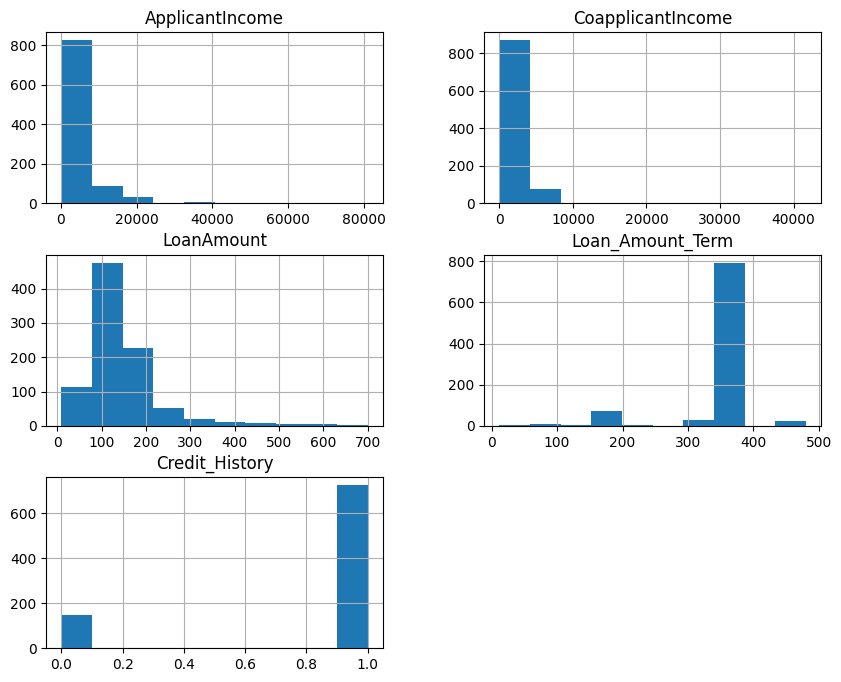

In [14]:
numeric_data.hist(figsize=(10,8))
plt.show()

The histograms show that ApplicantIncome, CoapplicantIncome, and LoanAmount are right-skewed, while Loan_Amount_Term is mostly concentrated around 360 and Credit_History around 1. These distributions suggest that outlier analysis and appropriate scaling should be considered during preprocessing.


###	3.6.5 Missing Values Analysis

In [15]:
missing_values = df.isna().sum()
print("Missing values in each column : ")
print(missing_values)

Missing values in each column : 
Loan_ID               0
Gender               24
Married               4
Dependents           23
Education             0
Self_Employed        50
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           32
Loan_Amount_Term     18
Credit_History       81
Property_Area         0
Loan_Status           0
dtype: int64


The analysis identified missing values in Credit_History (81), Self_Employed (50), LoanAmount (32), Gender (24), Dependents (23), Loan_Amount_Term (18), and Married (4). These missing values need to be handled during preprocessing to improve data completeness.


### 3.6.6 Boxplots for Numerical Attributes

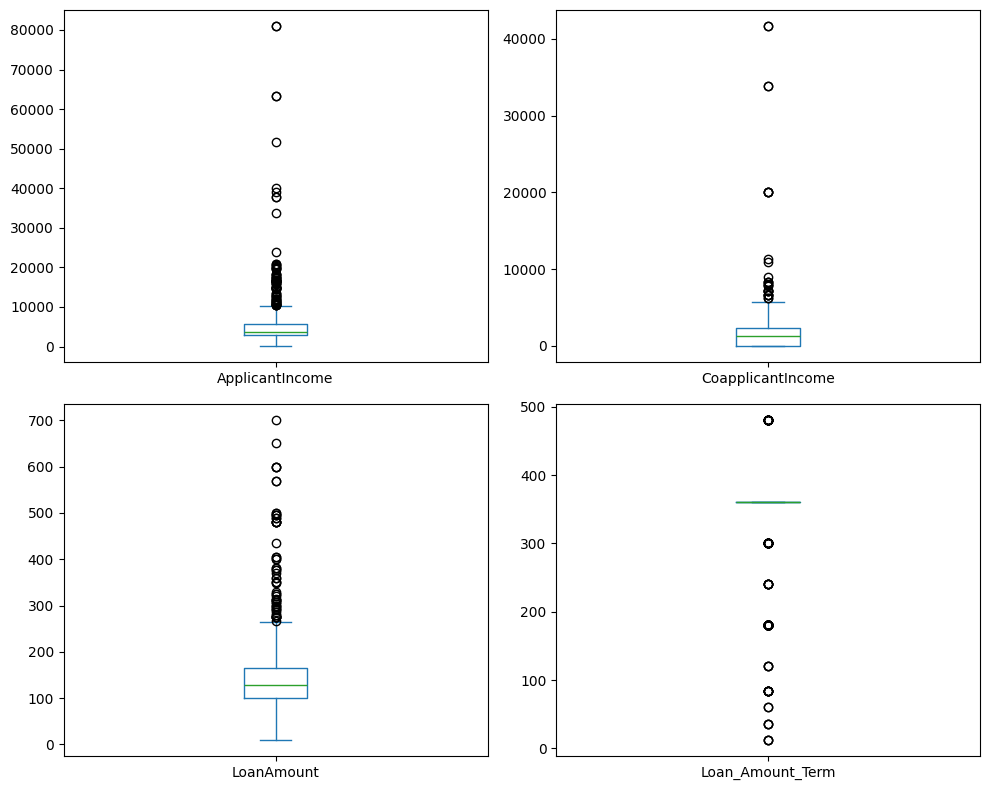

In [16]:
boxplot_data = df[["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term"]]
boxplot_data.plot (kind = "box", subplots = True, layout = (2, 2), figsize = (10, 8))
plt.tight_layout()
plt.show()

The boxplots show the distribution and potential outliers of the numerical attributes. Several outliers are visible, especially in ApplicantIncome, CoapplicantIncome, and LoanAmount. This indicates that the outliers should be further analyzed and considered during preprocessing.

### 3.6.7 Outlier Analysis

In [17]:
Q1 = boxplot_data.quantile(0.25)
Q3 = boxplot_data.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5*IQR
upper_bound = Q3 + 1.5*IQR

print("Lower Bound:")
print(lower_bound)
print("\nUpper Bound:")
print(upper_bound)


Lower Bound:
ApplicantIncome     -1544.5
CoapplicantIncome   -3459.0
LoanAmount              1.0
Loan_Amount_Term      360.0
dtype: float64

Upper Bound:
ApplicantIncome      10235.5
CoapplicantIncome     5765.0
LoanAmount             265.0
Loan_Amount_Term       360.0
dtype: float64


In [18]:
outliers = (boxplot_data < lower_bound) | (boxplot_data > upper_bound)

print("Number of outliers:")
print(outliers.sum())

Number of outliers:
ApplicantIncome       78
CoapplicantIncome     29
LoanAmount            60
Loan_Amount_Term     143
dtype: int64


Using the IQR method, 78 outliers were identified in ApplicantIncome, 29 in CoapplicantIncome, 60 in LoanAmount and 143 in Loan_Amount_Term. This shows that the numerical attributes contain unusual values that need to be considered during preprocessing.

### 3.6.8 Scatter Plot

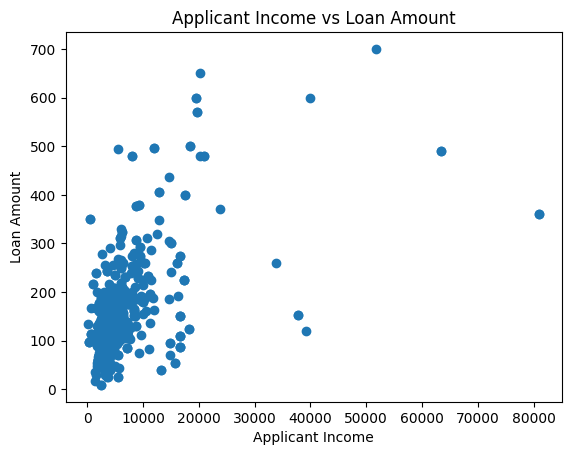

In [19]:
plt.scatter(df["ApplicantIncome"], df["LoanAmount"])
plt.xlabel("Applicant Income")
plt.ylabel("Loan Amount")
plt.title("Applicant Income vs Loan Amount")

plt.show()

The scatter plot shows the relationship between ApplicantIncome and LoanAmount. It suggests a positive relationship between the two attributes, with several unusual values far from the main cluster. These values indicate that the data may require preprocessing to handle potential outliers.

### 3.6.9 Bar Plot for a Nominal Attribute

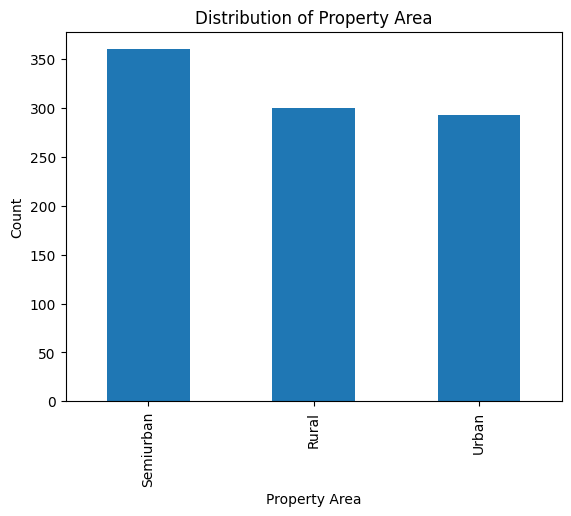

In [20]:
df["Property_Area"].value_counts().plot(kind="bar")
plt.xlabel("Property Area")
plt.ylabel("Count")
plt.title("Distribution of Property Area")

plt.show()

The bar plot shows the distribution of the Property_Area categories. Semiurban is the most common category, while Rural and Urban have lower and relatively similar counts. This distribution should be considered during preprocessing.

### 3.6.10 Class Label Distribution

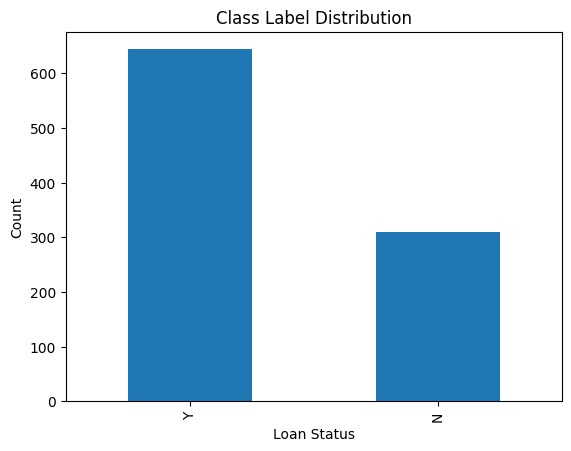

In [21]:
df["Loan_Status"].value_counts().plot(kind="bar")
plt.xlabel("Loan Status")
plt.ylabel("Count")
plt.title("Class Label Distribution")

plt.show()

The class label distribution shows that Loan_Status is imbalanced, with more approved (Y) than rejected (N) applications. This class imbalance should be considered during preprocessing.

### 3.6.11 Short Conclusion

The data analysis provided an overview and statistical summary of the dataset, including its numerical distributions and five-number summaries. The analysis also identified missing values, potential outliers, relationships between numerical attributes, differences in categorical distributions, and an imbalance in the class label. These findings show that preprocessing is needed to improve the dataset before further analysis and modeling.

## 4. Data Preprocessing

In [22]:
raw_df = pd.read_csv("Raw_dataset.csv")
print("Raw Dataset:")
raw_df.head()


Raw Dataset:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


### 4.1 Handling Missing Values

The dataset contains missing values in several attributes.
Missing values need to be handled before applying data mining techniques to improve data quality and avoid problems during the analysis and modeling process.

In [23]:
df.isnull().sum()

,0
Loan_ID,0
Gender,24
Married,4
Dependents,23
Education,0
Self_Employed,50
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,32
Loan_Amount_Term,18


#### 4.1.1 Categorical missing values
Missing values in categorical attributes were replaced using the mode.
The mode was used because these attributes contain categorical values.

In [24]:
categorical_columns = ['Gender', 'Married', 'Dependents', 'Self_Employed']
for column in categorical_columns:
    df[column]= df[column].fillna(df[column].mode()[0])

In [25]:
df[categorical_columns].isnull().sum()

,0
Gender,0
Married,0
Dependents,0
Self_Employed,0


#### 4.1.2 Numerical missing values
For 'LoanAmount', missing values were replaced with the median because the median is less affected by extreme values.

For 'Loan_Amount_Term' and 'Credit_History', missing values were replaced with the mode because these attributes contain a limited set of discrete values.

In [26]:
df['LoanAmount'] = df['LoanAmount'].fillna(df['LoanAmount'].median())
df['Loan_Amount_Term'] = df['Loan_Amount_Term'].fillna(
    df['Loan_Amount_Term'].mode()[0]
)

df['Credit_History'] = df['Credit_History'].fillna(
    df['Credit_History'].mode()[0]
  )

In [27]:
df[['LoanAmount' , 'Loan_Amount_Term' , 'Credit_History']].isnull().sum()

,0
LoanAmount,0
Loan_Amount_Term,0
Credit_History,0


### 4.2 Encoding

The categorical attributes in the dataset are Gender, Married, Dependents, Education, Self_Employed, Property_Area, and Loan_Status.

Label Encoding was applied to these categorical attributes using LabelEncoder. Each categorical value was converted into a numerical label while preserving the original categories. This changes the representation of the categorical attributes from text to numerical values without removing any records.

4.2.1 Before Encoding

In [28]:
categorical_columns = [
    'Gender',
    'Married',
    'Dependents',
    'Education',
    'Self_Employed',
    'Property_Area',
    'Loan_Status'
]

df[categorical_columns].head()

,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status
0,Male,No,0,Graduate,No,Urban,Y
1,Male,Yes,1,Graduate,No,Rural,N
2,Male,Yes,0,Graduate,Yes,Urban,Y
3,Male,Yes,0,Not Graduate,No,Urban,Y
4,Male,No,0,Graduate,No,Urban,Y


4.2.2 Applying Label Encoding

In [29]:
from sklearn.preprocessing import LabelEncoder

for column in categorical_columns:
    le = LabelEncoder()
    df[column] = le.fit_transform(df[column])

# 4.2.3 After Encoding

In [30]:
df[categorical_columns].head()

,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status
0,1,0,0,0,0,2,1
1,1,1,1,0,0,0,0
2,1,1,0,0,1,2,1
3,1,1,0,1,0,2,1
4,1,0,0,0,0,2,1


The before-and-after samples show that Loan_Status changed from text labels to numeric labels. The encoding preserved the approval categories and did not remove any records or change other attributes.

### 4.3 Outlier Handling
ApplicantIncome was selected because it contains extreme values that are considerably higher than most observations. These values may affect the analysis, so outlier handling was applied to this attribute.

The IQR (Interquartile Range) method was used to identify potential outliers. The first quartile (Q1) and third quartile (Q3) were calculated, and the IQR was obtained as the difference between them. Values below the lower bound or above the upper bound were considered potential outliers.Although these values were identified as outliers, they may represent valid observations rather than errors in the data.

4.3.1 Before Outlier Treatment

In [31]:
print("Number of rows:", len(df))
print("Maximum ApplicantIncome:", max(df['ApplicantIncome']))

Number of rows: 953
Maximum ApplicantIncome: 81002


#### 4.3.2 Applying Outlier Treatment

Records with ApplicantIncome below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR were excluded. This reduced the influence of extreme income values, although some excluded records may represent valid high-income applicants.

In [32]:
Q1 = df['ApplicantIncome'].quantile(0.25)
Q3 = df['ApplicantIncome'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_indices = df[
    (df['ApplicantIncome'] < lower_bound) |
    (df['ApplicantIncome'] > upper_bound)
].index

df_no_outlier = df.drop(outlier_indices)

print("Removed records:", len(outlier_indices))

Removed records: 78


4.3.3 After Outlier Treatment

In [33]:
print("Number of rows:", len(df_no_outlier))
print("Maximum ApplicantIncome:", max(df_no_outlier['ApplicantIncome']))

Number of rows: 875
Maximum ApplicantIncome: 10139


The treatment removed 78 records using the IQR method. The dataset decreased from 953 to 875 records, and the maximum ApplicantIncome decreased from 81002 to 10139.

In [34]:
df = df_no_outlier

first few records of the final preprocessed dataset after applying the preprocessing steps.

In [35]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,1,0,0,0,0,5849,0.0,128.0,360.0,1.0,2,1
1,LP001003,1,1,1,0,0,4583,1508.0,128.0,360.0,1.0,0,0
2,LP001005,1,1,0,0,1,3000,0.0,66.0,360.0,1.0,2,1
3,LP001006,1,1,0,1,0,2583,2358.0,120.0,360.0,1.0,2,1
4,LP001008,1,0,0,0,0,6000,0.0,141.0,360.0,1.0,2,1


In [36]:
df.shape

(875, 13)

### 4.4 Normalization
Numerical attributes were normalized to place their values on a common scale. Min-Max Normalization was applied to ApplicantIncome, CoapplicantIncome, LoanAmount, and Loan_Amount_Term, transforming their values to the range [0, 1].

In [37]:
colmuns_to_normalize = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']

print("Before Normalization:")
df[colmuns_to_normalize].head()

Before Normalization:


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term
0,5849,0.0,128.0,360.0
1,4583,1508.0,128.0,360.0
2,3000,0.0,66.0,360.0
3,2583,2358.0,120.0,360.0
4,6000,0.0,141.0,360.0


In [38]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
df[colmuns_to_normalize] = scaler.fit_transform(df[colmuns_to_normalize])

print("\nAfter Normalization:")
df[colmuns_to_normalize].head()


After Normalization:


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term
0,0.570528,0.000000,0.244856,0.74359
1,0.443788,0.036192,0.244856,0.74359
2,0.285314,0.000000,0.117284,0.74359
3,0.243568,0.056592,0.228395,0.74359
4,0.585644,0.000000,0.271605,0.74359


In [39]:
print("Minimum values after normalization:")
print(df[colmuns_to_normalize].min())
print("\nMaximum values after normalization:")
print(df[colmuns_to_normalize].max())

Minimum values after normalization:
ApplicantIncome      0.0
CoapplicantIncome    0.0
LoanAmount           0.0
Loan_Amount_Term     0.0
dtype: float64

Maximum values after normalization:
ApplicantIncome      1.0
CoapplicantIncome    1.0
LoanAmount           1.0
Loan_Amount_Term     1.0
dtype: float64


In [40]:
df.to_csv('Preprocessed_dataset.csv' , index = False)
print("Final dataset shape:" , df.shape)

Final dataset shape: (875, 13)


In [41]:
print("Final preprocessed dataset:")
df.head()

Final preprocessed dataset:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,1,0,0,0,0,0.570528,0.000000,0.244856,0.74359,1.0,2,1
1,LP001003,1,1,1,0,0,0.443788,0.036192,0.244856,0.74359,1.0,0,0
2,LP001005,1,1,0,0,1,0.285314,0.000000,0.117284,0.74359,1.0,2,1
3,LP001006,1,1,0,1,0,0.243568,0.056592,0.228395,0.74359,1.0,2,1
4,LP001008,1,0,0,0,0,0.585644,0.000000,0.271605,0.74359,1.0,2,1


In [42]:
from google.colab import files
files.download('Preprocessed_dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 5. Data Mining Technique

### 5.1 Classification: Decision Tree

Decision Tree classification was used to predict Loan_Status because it provides interpretable rules for classifying loan applications.

Two attribute selection measures were compared: Gini and Entropy (Information Gain). Each was evaluated using three training/testing partitions: 90/10, 80/20, and 70/30.

The implementation uses pandas for data handling and scikit-learn methods: train_test_split for partitioning, DecisionTreeClassifier for modeling, and accuracy_score and confusion_matrix for evaluation. The trees are visualized using plot_tree from sklearn.tree.

Loan_Status is the target variable. Loan_ID is excluded from the features because it is an identifier.

### 5.2 Clustering: K-means

K-means was used to discover groups of applicants with similar characteristics. Loan_ID and Loan_Status are excluded from the clustering features.

The implementation uses KMeans from sklearn.cluster. Candidate K values are evaluated using inertia_ for the within-cluster sum of squares and silhouette_score for the average Silhouette Coefficient.

Values of K from 2 to 10 were explored. K = 2, 3, and 5 were selected for detailed comparison. Matplotlib and Seaborn are used to visualize the evaluation results and clusters.

## 6. Evaluation and Comparison

### 6.1 Classification Using Decision Tree

6.1.1 Gini index

In [43]:
import pandas as pd
df = pd.read_csv("Preprocessed_dataset.csv")
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,1,0,0,0,0,0.570528,0.000000,0.244856,0.74359,1.0,2,1
1,LP001003,1,1,1,0,0,0.443788,0.036192,0.244856,0.74359,1.0,0,0
2,LP001005,1,1,0,0,1,0.285314,0.000000,0.117284,0.74359,1.0,2,1
3,LP001006,1,1,0,1,0,0.243568,0.056592,0.228395,0.74359,1.0,2,1
4,LP001008,1,0,0,0,0,0.585644,0.000000,0.271605,0.74359,1.0,2,1


Defining Features and Class Label

Loan_Status was selected as the class label. Loan_ID was excluded because it is an identifier and does not represent an applicant characteristic.

In [44]:
X = df.drop(columns=['Loan_Status', 'Loan_ID'])
y = df['Loan_Status']

In [45]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix


 6.1.1.1 90% Training and 10% Testing

In [46]:
X_train_90, X_test_10, y_train_90, y_test_10 = train_test_split(
    X, y, test_size=0.10, random_state=1
)

gini_90 = DecisionTreeClassifier(criterion='gini',random_state=1)

gini_90.fit(X_train_90, y_train_90)

y_pred_90 = gini_90.predict(X_test_10)

In [47]:
accuracy_90 = accuracy_score(y_test_10, y_pred_90)

print("Accuracy:", accuracy_90)

print("Confusion Matrix:")
print(confusion_matrix(y_test_10, y_pred_90))


Accuracy: 0.8863636363636364
Confusion Matrix:
[[19  5]
 [ 5 59]]


The 90/10 partition achieved an accuracy of 88.64%. The confusion matrix shows that most loan applications were classified correctly with 19 true negative predictions and 59 true positive predictions while 5 negative  cases and 5 positive cases were misclassified.

6.1.1.2 80% Training and 20% Testing

In [48]:
X_train_80, X_test_20, y_train_80, y_test_20 = train_test_split(
    X, y, test_size=0.20,random_state=1
)

gini_80 = DecisionTreeClassifier(criterion='gini',random_state=1)

gini_80.fit(X_train_80, y_train_80)

y_pred_80 = gini_80.predict(X_test_20)

In [49]:
accuracy_80 = accuracy_score(y_test_20, y_pred_80)

print("Accuracy:", accuracy_80)

print("Confusion Matrix:")
print(confusion_matrix(y_test_20, y_pred_80))

Accuracy: 0.8685714285714285
Confusion Matrix:
[[ 46  12]
 [ 11 106]]


The 80/20 partition achieved an accuracy of 86.86%. The confusion matrix shows that most loan applications were classified correctly, with 46 true negative predictions and 106 true positive predictions, while 12 negative cases and 11 positive cases were misclassified.


6.1.1.3 70% Training and 30% Testing

In [50]:
X_train_70, X_test_30, y_train_70, y_test_30 = train_test_split(
    X, y, test_size=0.30,random_state=1
)

gini_70 = DecisionTreeClassifier(criterion='gini',random_state=1)

gini_70.fit(X_train_70, y_train_70)

y_pred_70 = gini_70.predict(X_test_30)

In [51]:
accuracy_70 = accuracy_score(y_test_30, y_pred_70)

print("Accuracy:", accuracy_70)

print("Confusion Matrix:")
print(confusion_matrix(y_test_30, y_pred_70))

Accuracy: 0.8859315589353612
Confusion Matrix:
[[ 71  15]
 [ 15 162]]


The 70/30 partition achieved an accuracy of 88.59%. The confusion matrix shows that most loan applications were classified correctly, with 71 true negative predictions and 162 true positive predictions, while 15 negative cases and 15 positive cases were misclassified.

6.1.1.4 Gini Results Summary

In [52]:
gini_results = pd.DataFrame({
    'Partition': ['90/10', '80/20', '70/30'],
    'Accuracy': [accuracy_90, accuracy_80, accuracy_70]
})

gini_results

,Partition,Accuracy
0,90/10,0.886364
1,80/20,0.868571
2,70/30,0.885932


The 90/10 partition achieved the highest accuracy of 88.64%, followed by the 70/30 partition with 88.59%, while the 80/20 partition achieved 86.86%. Therefore, the 90/10 partition provided the best performance using the Gini index.

6.1.1.5 Gini decision tree visualization

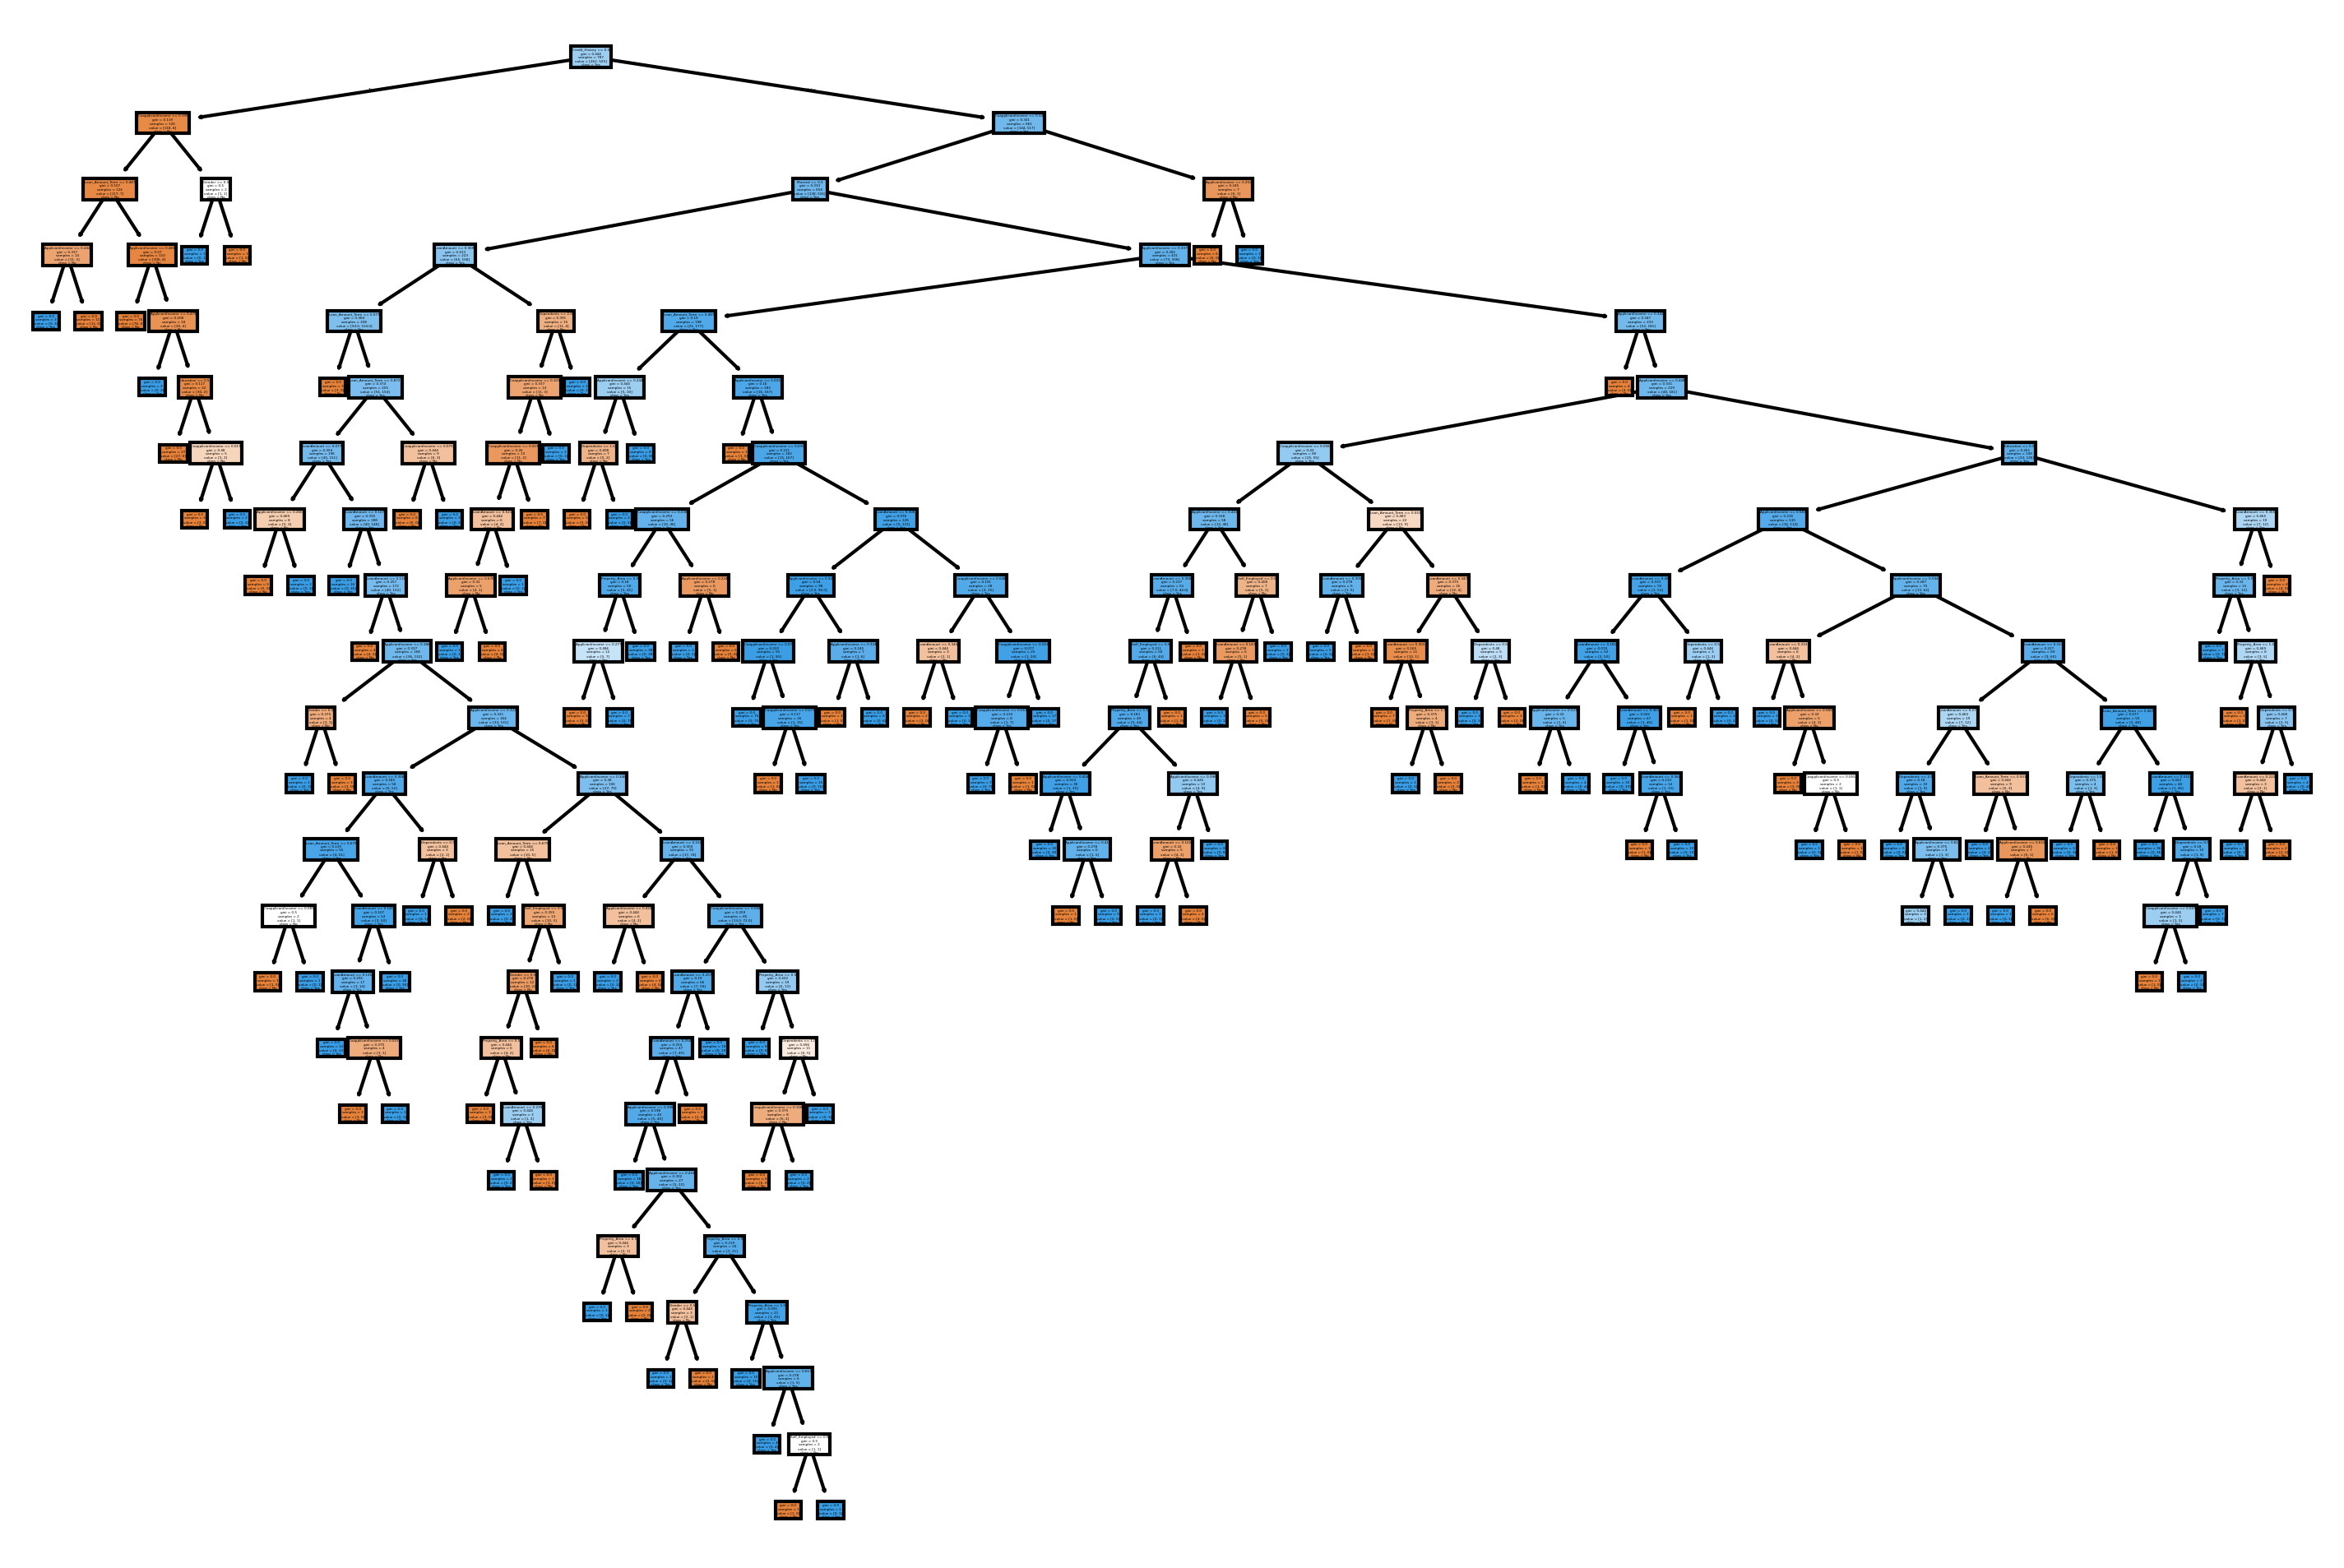

In [53]:
from sklearn import tree
import matplotlib.pyplot as plt

fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(12,8), dpi=300)

tree.plot_tree(
    gini_90,
    feature_names=X.columns,
    class_names=['No', 'Yes'],
    filled=True
);

plt.show()

The Decision Tree shows how the model splits the data using the most important attributes to classify loan applications into approved and not approved classes.

6.1.2 Entropy (Information Gain)

# 6.1.2.1 90% Training and 10% Testing

In [54]:
entropy_90 = DecisionTreeClassifier(criterion='entropy', random_state=1)

entropy_90.fit(X_train_90, y_train_90)

y_pred_entropy_90 = entropy_90.predict(X_test_10)

In [55]:
accuracy_entropy_90 = accuracy_score(y_test_10, y_pred_entropy_90)

print("Accuracy:", accuracy_entropy_90)

print("Confusion Matrix:")
print(confusion_matrix(y_test_10, y_pred_entropy_90))

Accuracy: 0.875
Confusion Matrix:
[[20  4]
 [ 7 57]]


The 90/10 partition achieved an accuracy of 87.5%. The confusion matrix shows that most loan applications were classified correctly, with 20 true negative predictions and 57 true positive predictions, while 4 negative cases and 7 positive cases were misclassified.

6.1.2.2 80% Training and 20% Testing

In [56]:
entropy_80 = DecisionTreeClassifier(criterion='entropy', random_state=1)

entropy_80.fit(X_train_80, y_train_80)

y_pred_entropy_80 = entropy_80.predict(X_test_20)


In [57]:
accuracy_entropy_80 = accuracy_score(y_test_20, y_pred_entropy_80)

print("Accuracy:", accuracy_entropy_80)

print("Confusion Matrix:")
print(confusion_matrix(y_test_20, y_pred_entropy_80))

Accuracy: 0.8742857142857143
Confusion Matrix:
[[ 46  12]
 [ 10 107]]


The 80/20 partition achieved an accuracy of 87.43%. The confusion matrix shows that most loan applications were classified correctly, with 46 true negative predictions and 107 true positive predictions, while 12 negative cases and 10 positive cases were misclassified.

6.1.2.3 70% Training and 30% Testing

In [58]:
entropy_70 = DecisionTreeClassifier(criterion='entropy', random_state=1)

entropy_70.fit(X_train_70, y_train_70)

y_pred_entropy_70 = entropy_70.predict(X_test_30)

In [59]:
accuracy_entropy_70 = accuracy_score(y_test_30, y_pred_entropy_70)

print("Accuracy:", accuracy_entropy_70)

print("Confusion Matrix:")
print(confusion_matrix(y_test_30, y_pred_entropy_70))

Accuracy: 0.870722433460076
Confusion Matrix:
[[ 73  13]
 [ 21 156]]


The 70/30 partition achieved an accuracy of 87.07%. The confusion matrix shows that most loan applications were classified correctly, with 73 true negative predictions and 156 true positive predictions, while 13 negative cases and 21 positive cases were misclassified.


 6.1.2.4 Entropy Results Summary

| Training / Testing | Accuracy |
|---|---|
| 90% / 10% | 87.50% |
| 80% / 20% | 87.43% |
| 70% / 30% | 87.07% |

The 90/10 partition achieved the highest accuracy at 87.50%. However, the accuracy values were very close across all three partitions, showing that the Entropy Decision Tree performed similarly with different training and testing sizes.


6.1.2.5 Entropy Decision Tree Visualization

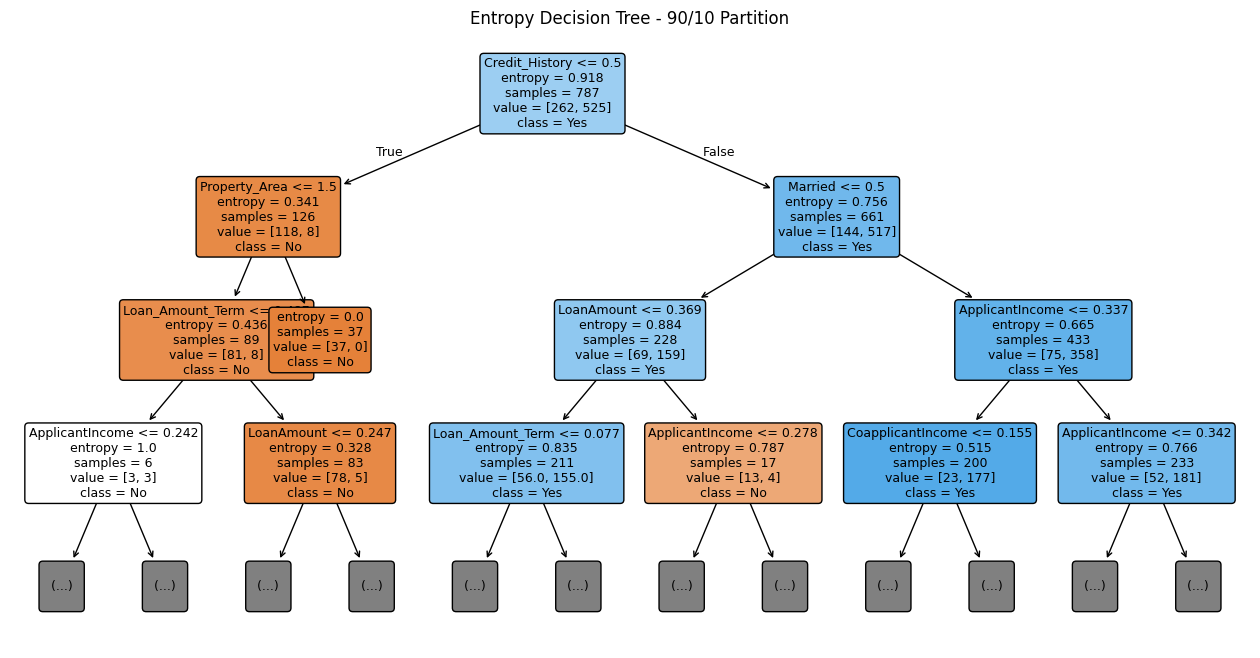

In [60]:
plt.figure(figsize=(16, 8))

tree.plot_tree(
    entropy_90,
    feature_names=X.columns,
    class_names=['No', 'Yes'],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Entropy Decision Tree - 90/10 Partition")
plt.show()


The Entropy Decision Tree shows that Credit_History is the first feature used to classify loan applications. Applications with Credit_History less than or equal to 0.5 are mostly classified as No, while applications with higher Credit_History are mostly classified as Yes. Other features such as Property_Area, Married, LoanAmount, and ApplicantIncome are also used in later decisions. This shows that the model uses different applicant characteristics to predict loan approval.

6.1.3 Gini vs. Entropy Comparison

| Training / Testing | Gini Accuracy | Entropy Accuracy | Better Method |
|---|---|---|---|
| 90% / 10% | 88.64% | 87.50% | Gini |
| 80% / 20% | 86.86% | 87.43% | Entropy |
| 70% / 30% | 88.59% | 87.07% | Gini |

Gini achieved higher accuracy in the 90/10 and 70/30 partitions, while Entropy performed slightly better in the 80/20 partition. The highest accuracy overall was 88.64%, achieved by Gini using the 90/10 partition. Based on these results, Gini performed slightly better overall for our dataset.

### 6.2 Clustering Evaluation

In [61]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("Dataset Shape:", df.shape)

Dataset Shape: (875, 13)


6.2.1 Elbow Method

The Elbow Method is used to determine the optimal number of clusters (K). It calculates the total within-cluster sum of squares for different values of K. The results are plotted to identify the elbow point.

In [62]:
# Range of clusters to try
k_range = range(2, 11)

# List to store WCSS values
wcss = []

# Calculate WCSS for each value of K
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

# Store results in a table
elbow_results = pd.DataFrame({
    'K': list(k_range),
    'Total Within-Cluster Sum of Squares': wcss
})

elbow_results

,K,Total Within-Cluster Sum of Squares
0,2,1451.046421
1,3,1154.002503
2,4,1071.488690
3,5,958.383564
4,6,892.451071
5,7,849.952526
6,8,820.000681
7,9,760.859427
8,10,709.066801


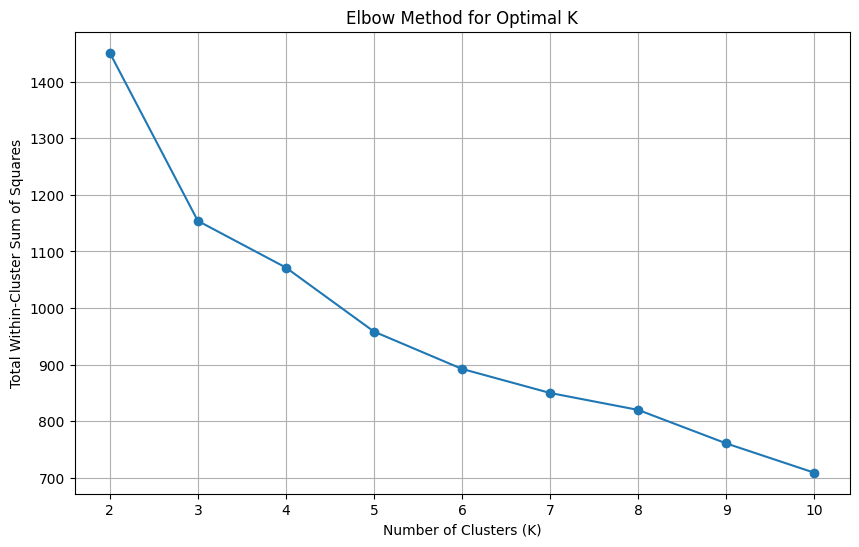

In [63]:
# Plot Elbow Method results
plt.figure(figsize=(10, 6))
plt.plot(k_range, wcss, marker='o')

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Total Within-Cluster Sum of Squares')
plt.xticks(list(k_range))
plt.grid(True)
plt.show()

The Elbow Method shows a significant decrease in WCSS when K increases from 2 to 3. After that, WCSS continues to decrease, but the reduction generally becomes smaller, with some variations.

K = 3 is considered a potential elbow point, while K = 5 is also considered for comparison because the curve starts showing a flattening behavior. Therefore, both values are retained as candidates for further evaluation.

6.2.2 Silhouette Coefficient

The Silhouette Coefficient is used to evaluate clustering quality by measuring how well data points fit within their assigned clusters and how well they are separated from other clusters. The average silhouette score is calculated for different values of K to help determine the optimal number of clusters.

In [64]:
# List to store silhouette scores
silhouette_avg_values = []

# Calculate silhouette score for each value of K
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X)

    silhouette_avg = silhouette_score(X, labels)
    silhouette_avg_values.append(silhouette_avg)

# Store results in a table
silhouette_results = pd.DataFrame({
    'K': list(k_range),
    'Average Silhouette Score': silhouette_avg_values
})

silhouette_results

,K,Average Silhouette Score
0,2,0.351561
1,3,0.276938
2,4,0.234122
3,5,0.227525
4,6,0.216758
5,7,0.211633
6,8,0.228269
7,9,0.226658
8,10,0.258284


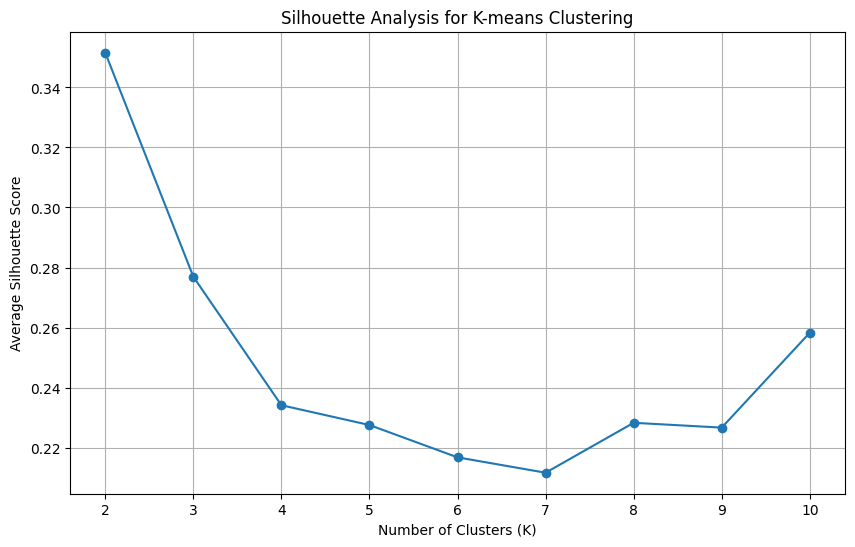

In [65]:
# Plot Silhouette results
plt.figure(figsize=(10, 6))
plt.plot(k_range, silhouette_avg_values, marker='o')

plt.title('Silhouette Analysis for K-means Clustering')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Average Silhouette Score')
plt.xticks(list(k_range))
plt.grid(True)
plt.show()

In [66]:
# Combine Elbow and Silhouette results
evaluation_results = pd.merge(
    elbow_results,
    silhouette_results,
    on='K'
)

evaluation_results

,K,Total Within-Cluster Sum of Squares,Average Silhouette Score
0,2,1451.046421,0.351561
1,3,1154.002503,0.276938
2,4,1071.488690,0.234122
3,5,958.383564,0.227525
4,6,892.451071,0.216758
5,7,849.952526,0.211633
6,8,820.000681,0.228269
7,9,760.859427,0.226658
8,10,709.066801,0.258284


6.2.3 Selection of K Values for Clustering Evaluation

Three different values of K (2, 3, and 5) were selected for further clustering evaluation based on the Elbow Method and Silhouette Coefficient results.

- **K = 2:** Selected because it achieved the highest average Silhouette Score (0.351561), indicating the best cluster separation among the tested values.
- **K = 3:** Selected because the Elbow curve shows a significant change in its slope around this value, making it a potential elbow point.
- **K = 5:** Selected to further examine the clustering performance after the initial decrease in WCSS and investigate the flattening behavior of the Elbow curve.

These values provide different clustering configurations for comparison using both evaluation metrics and cluster visualization.

6.2.4 Calinski-Harabasz Index

The Calinski-Harabasz Index was calculated for K = 2, 3, and 5 to provide an additional evaluation metric for selecting the optimal number of clusters. Higher values indicate better clustering performance according to this metric.

In [72]:
# Calinski-Harabasz Index for selected K values

from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score

selected_k = [2, 3, 5]

for k in selected_k:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X)

    ch_score = calinski_harabasz_score(X, labels)

    print("K =", k)
    print("Calinski-Harabasz Index =", ch_score)
    print("------------------------")

K = 2
Calinski-Harabasz Index = 462.452717482352
------------------------
K = 3
Calinski-Harabasz Index = 402.63950610539587
------------------------
K = 5
Calinski-Harabasz Index = 286.2504914223144
------------------------


Calinski-Harabasz Index Analysis

The Calinski-Harabasz Index was calculated for K = 2, 3, and 5. The highest score was obtained at K = 2 (462.45), followed by K = 3 (402.64) and K = 5 (286.25).

The Silhouette Score also supports K = 2, while the Elbow Method suggests K = 3 as a possible elbow point. Based on the majority rule, K = 2 was selected as the best number of clusters because it achieved the best results in two of the three evaluation methods.

### 6.3 Clustering Visualization and Comparison
In this section, K-means clustering is applied using the three selected values of K (2, 3, and 5). The resulting clusters are visualized and compared to identify the most suitable K and interpret the characteristics of each cluster.

In [67]:
# Apply K-means for three selected K values

selected_k = [2, 3, 5]

for k in selected_k:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans_result = kmeans.fit(X)

    print("K =", k)

    print("Average Silhouette Score:")
    print(silhouette_score(X, kmeans_result.labels_))

    print("Total Within-Cluster Sum of Squares:")
    print(kmeans_result.inertia_)

    print("-------------------------")

K = 2
Average Silhouette Score:
0.3515608081040287
Total Within-Cluster Sum of Squares:
1451.0464206852437
-------------------------
K = 3
Average Silhouette Score:
0.27693756299422845
Total Within-Cluster Sum of Squares:
1154.002503446649
-------------------------
K = 5
Average Silhouette Score:
0.22752483410082283
Total Within-Cluster Sum of Squares:
958.3835642336237
-------------------------


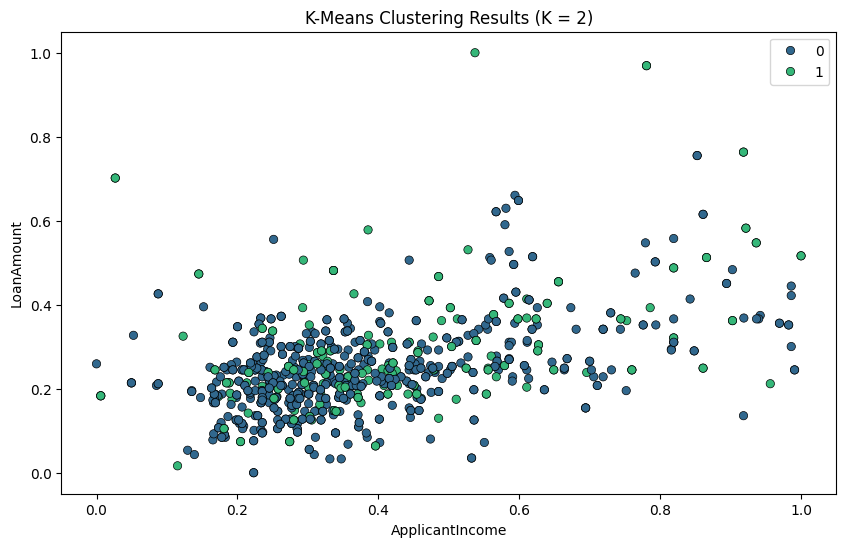

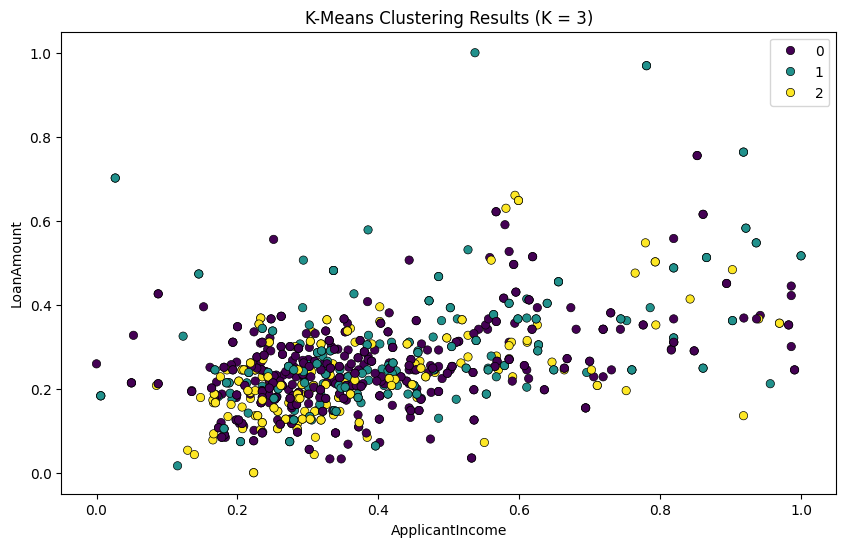

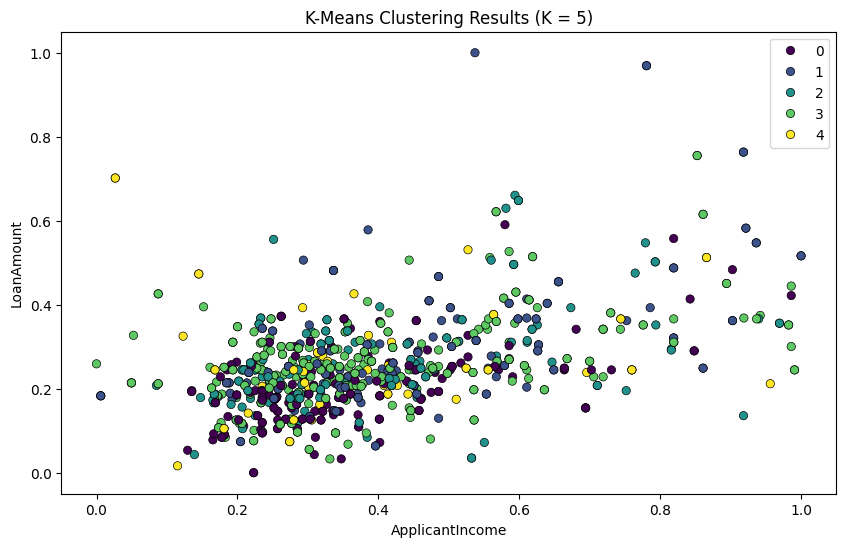

In [68]:
import seaborn as sns
for k in selected_k:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans_result = kmeans.fit(X)

    df['Cluster'] = kmeans_result.labels_

    plt.figure(figsize=(10, 6))

    sns.scatterplot(
        x='ApplicantIncome',
        y='LoanAmount',
        hue='Cluster',
        data=df,
        palette='viridis',
        edgecolor='k'
    )

    plt.title(f'K-Means Clustering Results (K = {k})')
    plt.xlabel('ApplicantIncome')
    plt.ylabel('LoanAmount')
    plt.legend()
    plt.show()

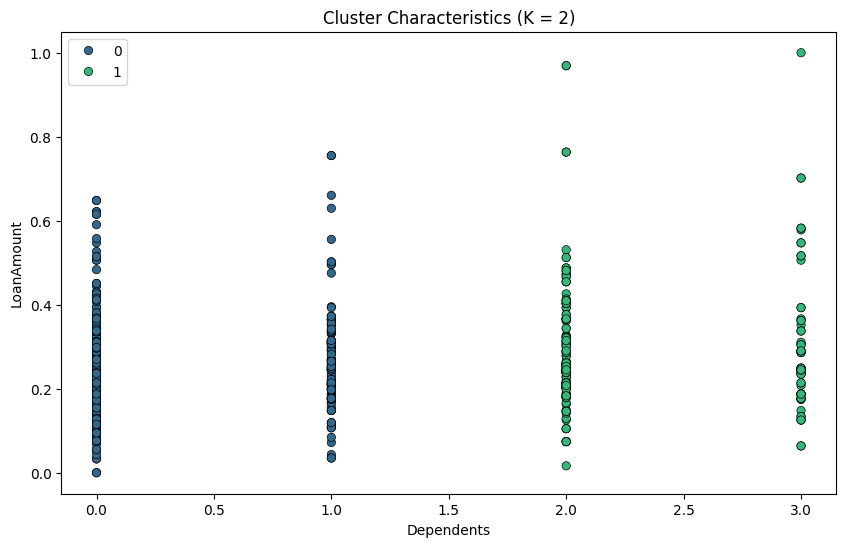

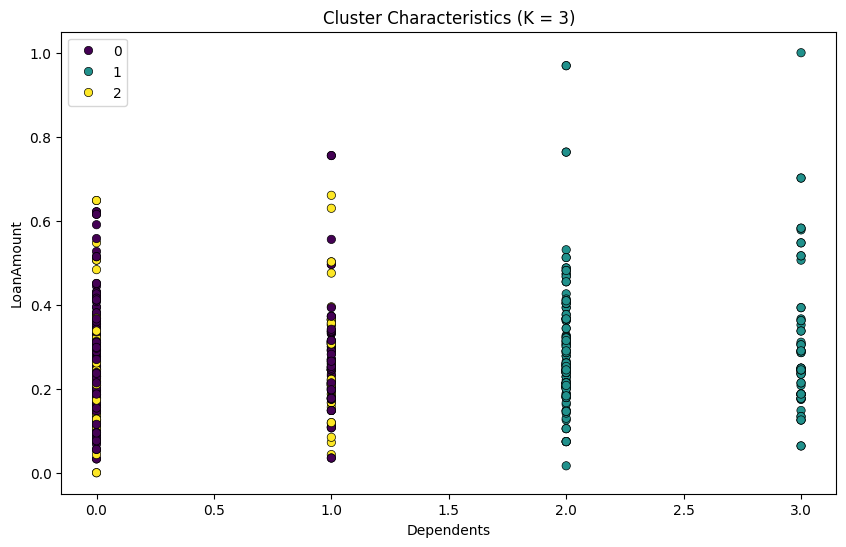

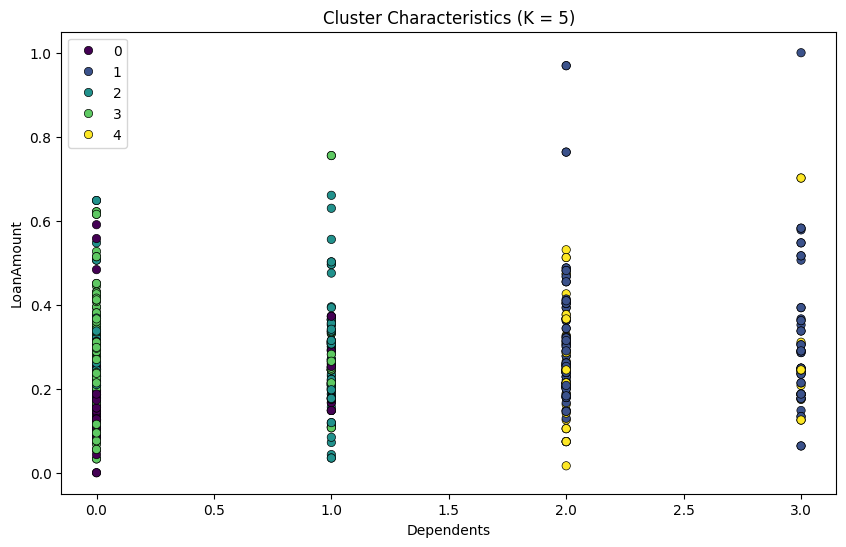

In [69]:
# Cluster Characteristics Visualization

for k in selected_k:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans_result = kmeans.fit(X)

    df['Cluster'] = kmeans_result.labels_

    plt.figure(figsize=(10, 6))

    sns.scatterplot(
        x='Dependents',
        y='LoanAmount',
        hue='Cluster',
        data=df,
        palette='viridis',
        edgecolor='k'
    )

    plt.title(f'Cluster Characteristics (K = {k})')
    plt.xlabel('Dependents')
    plt.ylabel('LoanAmount')
    plt.legend()
    plt.show()

In [70]:
# Comparison of clustering results

comparison_results = []

for k in [2, 3, 5]:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X)

    comparison_results.append({
        'K': k,
        'WCSS': kmeans.inertia_,
        'Silhouette Score': silhouette_score(X, labels)
    })

comparison_table = pd.DataFrame(comparison_results)
display(comparison_table)

,K,WCSS,Silhouette Score
0,2,1451.046421,0.351561
1,3,1154.002503,0.276938
2,5,958.383564,0.227525


In [71]:
# Analyze cluster characteristics for each K

for k in [2, 3, 5]:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X)

    cluster_data = X.copy()
    cluster_data['Cluster'] = labels

    print("K =", k)

    print("Cluster Sizes:")
    display(cluster_data['Cluster'].value_counts().sort_index())

    print("Cluster Characteristics:")
    display(cluster_data.groupby('Cluster').mean().T)

K = 2
Cluster Sizes:


,count
Cluster,
0,646
1,229


Cluster Characteristics:


Cluster,0,1
Gender,0.775542,0.938865
Married,0.572755,0.886463
Dependents,0.213622,2.314410
Education,0.232198,0.275109
Self_Employed,0.114551,0.144105
ApplicantIncome,0.384782,0.433989
CoapplicantIncome,0.040041,0.047779
LoanAmount,0.245522,0.289809
Loan_Amount_Term,0.706359,0.692196
Credit_History,0.845201,0.825328


K = 3
Cluster Sizes:


,count
Cluster,
0,448
1,229
2,198


... (2 outputs left out)

K = 5
Cluster Sizes:


,count
Cluster,
0,183
1,163
2,158
3,305
4,66


Cluster Characteristics:


Cluster,0,1,2,3,4
Gender,0.562842,0.950920,0.943038,0.816393,0.909091
Married,0.000000,0.871166,0.955696,0.718033,0.924242
Dependents,0.120219,2.319018,0.512658,0.114754,2.303030
Education,0.202186,0.269939,0.208861,0.262295,0.287879
Self_Employed,0.131148,0.171779,0.107595,0.108197,0.075758
ApplicantIncome,0.359352,0.454588,0.392683,0.395947,0.383115
CoapplicantIncome,0.031121,0.039054,0.041201,0.044793,0.069328
LoanAmount,0.202681,0.302444,0.264599,0.261344,0.258605
Loan_Amount_Term,0.721031,0.721095,0.677702,0.712400,0.620824
Credit_History,0.852459,0.828221,0.835443,0.845902,0.818182


6.3.1 Comparison of Clustering Results

K-means clustering was applied using K = 2, 3, and 5. The clustering results were compared using WCSS, Average Silhouette Score, and Calinski-Harabasz Index.

Throughout this section, averages of Dependents refer to encoded category values, not exact numbers of dependents; code 3 represents three or more dependents.

K = 2 achieved the highest Silhouette Score (0.3516), followed by K = 3 (0.2769) and K = 5 (0.2275), indicating better cluster separation for K = 2.

The Calinski-Harabasz Index also showed that K = 2 achieved the highest score (462.45), followed by K = 3 (402.64) and K = 5 (286.25), further supporting K = 2.

Although WCSS decreased as K increased, a lower WCSS alone does not indicate better clustering because increasing K generally reduces within-cluster distances.

6.3.2 Interpretation of K = 2

For K = 2, the dataset was divided into two clusters containing 646 and 229 records.

Cluster 0 has fewer dependents on average (0.214), with lower normalized ApplicantIncome (0.385) and LoanAmount (0.246).

Cluster 1 has more dependents on average (2.314), with higher normalized ApplicantIncome (0.434) and LoanAmount (0.290).

The main difference between the clusters is the number of dependents. Their average Credit_History values are relatively similar.

6.3.3 Interpretation of K = 3

For K = 3, the dataset was divided into three clusters containing 448, 229, and 198 records.

Cluster 0 has a low average number of dependents (0.201), with intermediate income and loan amount values.

Cluster 1 has the highest average number of dependents (2.314), ApplicantIncome (0.434), and LoanAmount (0.290).

Cluster 2 has relatively few dependents (0.242), with lower ApplicantIncome (0.366) and LoanAmount (0.234).

K = 3 provides additional segmentation, but its Silhouette Score is lower than that of K = 2.

6.3.4 Interpretation of K = 5

For K = 5, the dataset was divided into five clusters containing 183, 163, 158, 305, and 66 records.

Cluster 0 has relatively few dependents and a low average loan amount.

Cluster 1 has the highest average ApplicantIncome and LoanAmount, along with a high average number of dependents.

Cluster 2 has relatively few dependents and intermediate loan amount values.

Cluster 3 is the largest cluster, containing 305 records, with a low average number of dependents.

Cluster 4 is the smallest cluster, containing 66 records, and has a relatively high average number of dependents.

K = 5 provides more detailed segmentation, but its lower Silhouette Score indicates weaker overall separation according to this metric.

6.3.5 Best K Selection

Three different values of K (2, 3, and 5) were evaluated using the Elbow Method, Silhouette Score, and Calinski-Harabasz Index.

The Elbow Method suggested K = 3 as a potential elbow point, while K = 5 was also considered for comparison.

The Silhouette Score showed that K = 2 achieved the highest score (0.3516), compared to K = 3 (0.2769) and K = 5 (0.2275), indicating better cluster separation.

Similarly, the Calinski-Harabasz Index showed that K = 2 achieved the highest score (462.45), followed by K = 3 (402.64) and K = 5 (286.25).

Since the evaluation methods suggested different values of K, the majority rule was applied to select the best clustering configuration. Both the Silhouette Score and Calinski-Harabasz Index supported K = 2, while the Elbow Method suggested K = 3.

Therefore, based on the majority rule, K = 2 was selected as the best number of clusters, as it was supported by two out of the three evaluation methods and provided better cluster separation among the tested configurations.

## 7. Findings and Discussion

### 7.1 Classification Findings

Gini achieved higher test accuracy in two of the three partitions: 90/10 and 70/30. Entropy performed slightly better in the 80/20 partition. Therefore, Gini was preferred overall in these experiments.

The highest observed accuracy was 88.64%, achieved by Gini with the 90/10 partition. However, its result was very close to the 88.59% achieved with the 70/30 partition. These experiments do not establish that a 90/10 split will always perform best.

The confusion matrix for the best-performing configuration contained 19 correctly classified rejected applications and 59 correctly classified approved applications. Five rejected applications were predicted as approved, and five approved applications were predicted as rejected.

The Gini Decision Tree trained using the 90/10 partition was selected as the final classification model because it achieved the highest observed test accuracy (88.64%). Its root splits on Credit_History at a threshold of 0.5, making credit history the first characteristic used to separate applicants. Both main branches then split on CoapplicantIncome. Later decisions also use attributes such as Loan_Amount_Term, Married, and ApplicantIncome. The tree therefore shows how combinations of credit history, income, and other applicant characteristics lead to approved or rejected predictions, rather than relying on a single attribute. These rules describe patterns learned from this dataset and should be interpreted alongside the limitations discussed below.

The displayed Entropy tree uses Credit_History at its root, showing its importance in that fitted model. The tree visualizations help explain how combinations of applicant characteristics lead to approval predictions. These relationships describe patterns in the dataset and do not establish causation.

### 7.2 Clustering Findings

Among the tested K values from 2 to 10, K = 2 achieved the highest average Silhouette Score, approximately 0.3516. For K = 3 and K = 5, the scores were approximately 0.2769 and 0.2275, respectively.

Although WCSS decreased as K increased, this alone does not establish better clustering. Increasing the number of clusters generally reduces within-cluster variation.

For K = 2, the clusters contained 646 and 229 applicants. Cluster 0 had lower average encoded Dependents values, normalized ApplicantIncome, and normalized LoanAmount. Cluster 1 had higher averages for these attributes. Dependents is an encoded category, with code 3 representing three or more dependents; its mean should not be interpreted as an exact average family size.

K = 3 and K = 5 provided more detailed segmentation but lower Silhouette Scores. The Elbow curve suggested K = 3 as a possible candidate, whereas Silhouette favored K = 2. Thus, K = 2 is the current preference based on Silhouette and interpretability; the two evaluation approaches did not produce unanimous agreement.

The cluster plots illustrate similarities and overlap between applicant groups. Because each scatter plot displays only two attributes, it does not show the complete separation in the full feature space.

### 7.3 Meaning and Practical Value

Classification addresses the prediction of loan approval status, while clustering reveals groups of applicants with similar characteristics. Together, they provide complementary information: predicted approval outcomes and a description of applicant segments.

The clustering results should not be interpreted as approved and rejected classes because Loan_Status was excluded from the clustering features. The Silhouette Score of approximately 0.35 also indicates that the groups are not completely separated.

### 7.4 Comparison with the Research Paper

Badhan et al. [1] investigated the same general problem of loan approval prediction using several classification algorithms.

Table III of their paper reports a Decision Tree test accuracy of 68.33% and a Random Forest test accuracy of 82.5%. Our highest observed Decision Tree accuracy was 88.64%.

These numerical differences do not demonstrate that our model is superior. The paper describes a dataset of 615 rows and 13 columns, whereas our raw dataset contains 953 rows and 13 columns, with 875 rows remaining after preprocessing. The data sources, preprocessing procedures, and experimental settings also differ.

The paper contains an inconsistency between its results narrative and Table III concerning Decision Tree accuracy. The comparison above uses the explicitly labeled test result in Table III.

Our tree analysis also highlights Credit_History, which the paper discusses as an important attribute. This provides a qualitative similarity between the findings, although the experiments differ.

The paper focuses on classification and does not report K-means results. Therefore, our clustering findings provide an additional exploratory view of applicant groups rather than a direct comparison with the paper.

### 7.5 Limitations

The preprocessed dataset contains 302 duplicate rows beyond their first occurrences. Identical records may occur in both training and testing sets, potentially inflating classification accuracy. The reported accuracy should therefore be interpreted cautiously until the experiments are repeated with duplicates handled appropriately.

Preprocessing was performed before splitting the data, so information from the test set influenced the preprocessing statistics. Future experiments should fit preprocessing steps using training data only.

K-means was applied to a mixture of normalized numerical attributes and numerically encoded categories. The encoding and differences in attribute scales can influence the resulting groups. The clusters should therefore be treated as exploratory patterns.

## 8. References

[1] A. Badhan, A. Rana, S. S. Malhi, P. Kaur, and B. Saha, “A Comparative Analysis for Loan Approval Prediction using Machine Learning,” in 2024 International Conference on Electrical Electronics and Computing Technologies (ICEECT), 2024, doi: 10.1109/ICEECT61758.2024.10738925.

[2] “Loan Approval Prediction Dataset,” Kaggle. [Online]. Available: https://www.kaggle.com/datasets/priyanshsharma6207/loan-approval-prediction-dataset [Accessed: Nov. 8, 2026].